In [1]:
import sys
sys.path.insert(0, "..")

In [ ]:
from importlib import reload

import fonctions.parametres_phy as pp
import fonctions.parametres_numeriques as pn

reload(pp)
reload(pn)

ParametresPhysiques = pp.ParametresPhysiques
Paramnum = pn.Paramnum


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from fonctions.hamiltonien import diagonalisation
from fonctions.parametres_swm import ParametresSWM
from fonctions.parametres_numeriques import Paramnum
from fonctions.fermi_energy import energie_fermi
import fonctions.unites_phy  as unites_phy
from fonctions.parametres_phy import ParametresPhysiques

In [32]:
# objet
param_num=Paramnum(B=1,Nq=401,N_omega=1200,omega_cm_max=250,omega_cm_min=-250)
param_swm=ParametresSWM()
param_phys = ParametresPhysiques(eta_cm=0.3)

In [6]:
#
valeurs_q = np.linspace(-0.5, 0.5, param_num.Nq)

# Grille des fréquences en cm⁻¹
omega_cm_values = np.linspace(
    param_num.omega_cm_min,
    param_num.omega_cm_max,
    param_num.N_omega
)

In [27]:
## On cree 3 liste 
#M_i: pour mettre les elements de matrices pour chaque transitions.

#Delta E_i: differences entre energies.

#tranistions:  (n,$\lambda_1$,n-2,$\lambda_2$,q)

EF= energie_fermi(param_num.B,param_swm,param_num)

M_liste = []
DeltaE_liste = []
transitions_liste = []

for q in valeurs_q: # boucle sur touts les points q

    Gamma = param_swm.Gamma(q)

    for n in range(2, param_num.n_max+1):

        energies_initiales, vecteurs_initiaux = diagonalisation(
            n, param_num.B, q, param_swm
        )

        energies_finales, vecteurs_finaux = diagonalisation(
            n - 2, param_num.B, q, param_swm
        )

        for indice_lambda1 in range(len(energies_initiales)):
            for indice_lambda2 in range(len(energies_finales)):

                E_initiale = energies_initiales[indice_lambda1] # energie(n,lambda,q) initiale
                E_finale = energies_finales[indice_lambda2]

                if E_initiale < EF and E_finale > EF:
                        
                    x1 = vecteurs_finaux[0, indice_lambda2]
                    x4 = vecteurs_initiaux[3, indice_lambda1]

                    M = Gamma**2 * np.abs(np.conj(x1) * x4)**2
                    DeltaE = E_finale - E_initiale

                    M_liste.append(M)
                    DeltaE_liste.append(DeltaE)
                    transitions_liste.append(
    (n, indice_lambda1, n - 2, indice_lambda2, q)
)
                    
M_tableau = np.array(M_liste) # tableau numpy
DeltaE_tableau = np.array(DeltaE_liste)

print(len(M_liste))
print(len(DeltaE_liste))
print(len(transitions_liste))

89867
89867
89867


In [28]:


# Conversion des fréquences en eV
omega_ev = omega_cm_values * unites_phy.cm1_to_eV

# Élargissement converti en eV
eta = param_phys.eta_cm * unites_phy.cm1_to_eV

# Facteur de couplage : à vérifier séparément
C_B = 10e-10

def Pi_plus_moins(omega_ev, M_tableau, DeltaE_tableau, eta, C_B):

    D = 1.0 / (
        omega_ev[:, None]
        - DeltaE_tableau[None, :]
        + 1j * eta
    )

    Pi_values = C_B * np.dot(D, M_tableau)

    return Pi_values

Pi_plus_moins_values = Pi_plus_moins(
    omega_ev,
    M_tableau,
    DeltaE_tableau,
    eta,  # correction : eta en eV
    C_B
)



In [31]:
for i, Delta in enumerate(DeltaE_liste):
    if 20 * unites_phy.cm1_to_eV < Delta < 30 * unites_phy.cm1_to_eV:
        print(transitions_liste[i])

(2, 1, 0, 0, -0.2)
(2, 1, 0, 0, -0.19857142857142857)
(2, 1, 0, 0, -0.19714285714285712)
(2, 1, 0, 0, -0.19571428571428573)
(2, 1, 0, 0, -0.19428571428571428)
(2, 1, 0, 0, -0.19285714285714284)
(2, 1, 0, 0, -0.19142857142857145)
(2, 1, 0, 0, -0.19)
(2, 1, 0, 0, -0.18857142857142856)
(2, 1, 0, 0, 0.1885714285714286)
(2, 1, 0, 0, 0.18999999999999995)
(2, 1, 0, 0, 0.1914285714285714)
(2, 1, 0, 0, 0.19285714285714284)
(2, 1, 0, 0, 0.19428571428571428)
(2, 1, 0, 0, 0.19571428571428573)
(2, 1, 0, 0, 0.19714285714285718)
(2, 1, 0, 0, 0.19857142857142862)
(2, 1, 0, 0, 0.19999999999999996)


<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
C:\Users\User\AppData\Local\Temp\ipykernel_7204\4219963655.py:14: SyntaxWarning: invalid escape sequence '\m'
  """plt.plot(


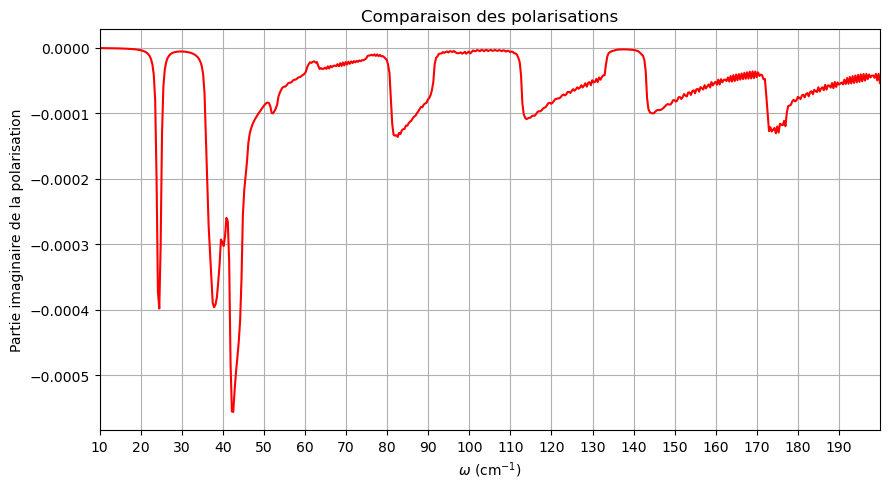

In [30]:
Pi_moins_plus_values = np.conj(
    Pi_plus_moins_values[::-1]
)

plt.figure(figsize=(9, 5))

plt.plot(
    omega_cm_values,
    np.imag(Pi_plus_moins_values),
    color="red",
    label=r"$\mathrm{Im}\,\Pi_{+-}(\omega)$"
)

"""plt.plot(
    omega_cm_values,
    -np.imag(Pi_plus_moins_values),
    color="blue",
    linestyle="-",
    label=r"$\mathrm{Im}\,\Pi_{-+}(-\omega)$"
)"""

plt.xlim(10, 200)
plt.xticks(np.arange(10, 200, 10))
plt.xlabel(r"$\omega$ (cm$^{-1}$)")
plt.ylabel("Partie imaginaire de la polarisation")
plt.title("Comparaison des polarisations")
#plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


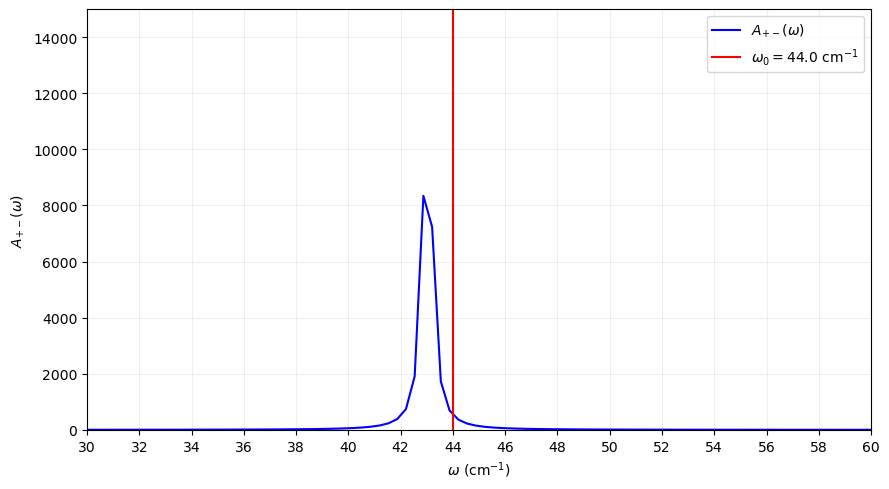

In [11]:
eta_ph=0.2*unites_phy.cm1_to_eV
# Conversion de la frequence du phonon et de la grille en eV
omega_0 = param_phys.omega_0_cm * unites_phy.cm1_to_eV

# Calcul de Pi_-+(omega) = conj(Pi_+-(−omega))
# La grille omega_cm_values est symétrique autour de zéro.
Pi_moins_plus_values = np.conj(
    Pi_plus_moins_values[::-1]
)

# Fonction de Green du phonon libre D0_+-
D0_plus_moins_values = (
    2 * omega_0
    / ((omega_ev + 1j * eta_ph)**2 - omega_0**2)
)

# Fonction de Green du phonon avec interaction électronique
# On utilise Pi_-+ dans le dénominateur
D_plus_moins_values = (
    D0_plus_moins_values
    / (1 - D0_plus_moins_values * Pi_moins_plus_values)
)

# Fonction spectrale A_+-
A_plus_moins_values = (
    -1 / np.pi
) * np.imag(D_plus_moins_values)


# Tracé de la fonction spectrale
plt.figure(figsize=(9, 5))

plt.plot(
    omega_cm_values,
    A_plus_moins_values,
    color="blue",
    label=r"$A_{+-}(\omega)$"
)

plt.axvline(
    x=param_phys.omega_0_cm,
    color="red",
    linestyle="-",
    linewidth=1.5,
    label=rf"$\omega_0 = {param_phys.omega_0_cm}\ \mathrm{{cm}}^{{-1}}$"
)

plt.xlabel(r"$\omega$ (cm$^{-1}$)")
plt.ylabel(r"$A_{+-}(\omega)$")
plt.xlim(30, 60)
plt.ylim(-10,15000)
plt.xticks(np.arange(30, 61, 2))
plt.grid(True, alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()